## Correlation, Regression, and Inference

### Learning Goals
* Calculate and interpret Pearson's correlation coefficient.
* Fit a simple linear regression model using Ordinary Least Squares (OLS).
* Interpret regression parameters (slope and intercept), residuals, and estimation uncertainty.
* Avoid common causal fallacies and validate model assumptions using residual diagnostics.

---

### 1. Correlation and Simple Linear Regression

When examining the relationship between two continuous variables, we look at both the strength of their association and how one can predict another:
* **Pearson Correlation ($r$):** Measures the strength and direction of the *linear* relationship between $X$ and $Y$, ranging from $-1$ to $+1$.
* **Simple Linear Regression:** Models the conditional expectation of $Y$ given $X$ using a straight line:
  $$
  \hat{y} = \beta_0 + \beta_1 x
  $$
  where $\beta_0$ is the intercept and $\beta_1$ is the slope.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(12)
x = np.linspace(0, 10, 60)
y = 2.5 * x + 4 + rng.normal(0, 5, size=len(x))

# Fit simple linear regression
fit = stats.linregress(x, y)

print(f"Pearson Correlation (r): {fit.rvalue:.4f}")
print(f"Slope (beta_1): {fit.slope:.4f}")
print(f"Intercept (beta_0): {fit.intercept:.4f}")
print(f"Slope p-value: {fit.pvalue:.4e}")

Pearson Correlation (r): 0.8739
Slope (beta_1): 2.7845
Intercept (beta_0): 3.2995
Slope p-value: 8.0812e-20


### 2. Plotting the Fitted Line

Visualizing the scatter plot alongside the fitted OLS regression line allows us to assess the overall trend and spot any obvious departures from linearity.

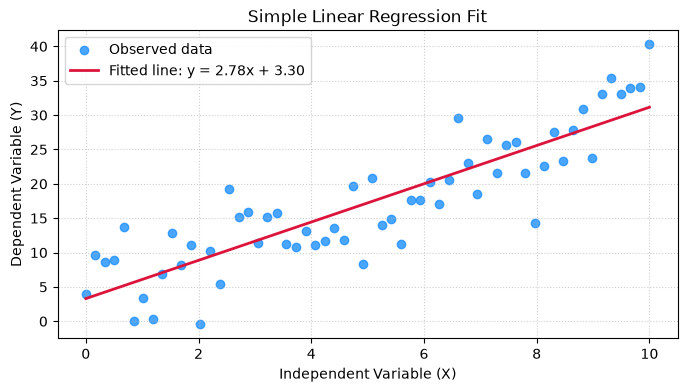

In [2]:
plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.8, color='dodgerblue', label="Observed data")
plt.plot(x, fit.intercept + fit.slope * x, color='crimson', linewidth=2, label=f"Fitted line: y = {fit.slope:.2f}x + {fit.intercept:.2f}")
plt.xlabel("Independent Variable (X)")
plt.ylabel("Dependent Variable (Y)")
plt.title("Simple Linear Regression Fit")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### 3. Residual Diagnostics

A residual is the vertical difference between an observed value and the model's predicted value ($e_i = y_i - \hat{y}_i$). Analyzing residuals is critical for verifying model assumptions:
* Residuals should appear randomly scattered around zero with constant variance (homoscedasticity).
* Patterns, curves, or fan shapes in residual plots indicate non-linearity or heteroscedasticity.

<>:7: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:7: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/tmp/ipykernel_2853/3364245086.py:7: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  plt.xlabel("Predicted Values ($\hat{y}$)")
/tmp/ipykernel_2853/3364245086.py:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw s

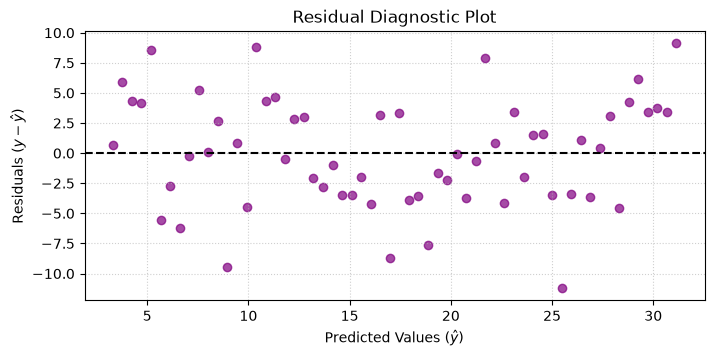

In [4]:
predicted = fit.intercept + fit.slope * x
residuals = y - predicted

plt.figure(figsize=(8, 3.5))
plt.scatter(predicted, residuals, color='purple', alpha=0.7)
plt.axhline(0, color='black', linestyle="--", linewidth=1.5)
plt.xlabel("Predicted Values ($\hat{y}$)")
plt.ylabel("Residuals ($y - \hat{y}$)")
plt.title("Residual Diagnostic Plot")
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### Cautions and Limitations

> **Critical Caveats:** 
> * **Correlation $\neq$ Causation:** A strong statistical association does not establish a causal mechanism; omitted variables or confounding factors may be at play.
> * **Assumption Checks:** Always verify linearity, independence of errors, constant variance, and check for influential outliers before trusting regression inference or $p$-values.

---

### Exercises

Try each problem before running the verification code below:

1. Interpret the slope ($\beta_1$) in the specific units of $X$ and $Y$.
2. Provide a practical example of confounding in a regression context.
3. Explain why inspecting a residual plot is more informative than relying solely on the coefficient of determination ($R^2$).

In [5]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Interpreting the Slope:")
print(f"   - For every 1-unit increase in X, the model predicts that Y changes (increases) by approximately {fit.slope:.2f} units.")

print("\n2. Example of Confounding:")
print("   - Ice cream sales and drowning rates are strongly correlated, but temperature acts as a confounder;")
print("     hotter weather increases both ice cream consumption and swimming activity.")

print("\n3. Why Inspect Residuals over R-squared:")
print("   - R-squared only summarizes the proportion of variance explained; a high R-squared can mask severe")
print("     non-linear patterns or heteroscedasticity that a residual diagnostic plot instantly reveals.")

=== Exercise Solutions & Checks ===

1. Interpreting the Slope:
   - For every 1-unit increase in X, the model predicts that Y changes (increases) by approximately 2.78 units.

2. Example of Confounding:
   - Ice cream sales and drowning rates are strongly correlated, but temperature acts as a confounder;
     hotter weather increases both ice cream consumption and swimming activity.

3. Why Inspect Residuals over R-squared:
   - R-squared only summarizes the proportion of variance explained; a high R-squared can mask severe
     non-linear patterns or heteroscedasticity that a residual diagnostic plot instantly reveals.
